In [1]:
import pandas as pd

DATA_PATH = "../data/raw/"
PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(DATA_PATH + "orders.csv")
order_products_prior = pd.read_csv(DATA_PATH + "order_products__prior.csv")
products = pd.read_csv(DATA_PATH + "products.csv")
departments = pd.read_csv(DATA_PATH + "departments.csv")

user_features = pd.read_csv(
    PROCESSED_PATH + "user_features.csv",
    index_col=0
)

# # Step 1: 算每筆訂單的 basket size
# order_size = (
#     order_products_prior
#     .groupby("order_id")
#     .size()
#     .reset_index(name="basket_size")
# )

# # Step 2: 合併 user_id
# order_size = order_size.merge(
#     orders[["order_id", "user_id"]],
#     on="order_id",
#     how="left"
# )

# # Step 3: 算每個 user 平均 basket size
# avg_basket_size = (
#     order_size
#     .groupby("user_id")["basket_size"]
#     .mean()
# )

# # Step 4: 合併回 user_features
# user_features["avg_basket_size"] = avg_basket_size

# # Step 5: 查看結果
# user_features.head()

In [2]:
user_orders = orders[[
    "order_id",
    "user_id"
]]

order_detail = order_products_prior.merge(
    user_orders,
    on="order_id",
    how="left"
)

order_detail = order_detail.merge(
    products,
    on="product_id",
    how="left"
)

order_detail = order_detail.merge(
    departments,
    on="department_id",
    how="left"
)

order_detail.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,product_name,aisle_id,department_id,department
0,2,33120,1,1,202279,Organic Egg Whites,86,16,dairy eggs
1,2,28985,2,1,202279,Michigan Organic Kale,83,4,produce
2,2,9327,3,0,202279,Garlic Powder,104,13,pantry
3,2,45918,4,1,202279,Coconut Butter,19,13,pantry
4,2,30035,5,0,202279,Natural Sweetener,17,13,pantry


In [3]:
department_counts = pd.crosstab(
    order_detail["user_id"],
    order_detail["department"]
)

department_counts.head()

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,13,3,0,0,13,0,0,...,2,0,0,0,0,1,0,0,5,22
2,0,0,2,9,3,0,1,48,21,0,...,0,3,1,0,0,11,1,0,36,42
3,0,0,0,3,0,0,0,21,2,4,...,1,0,0,0,0,4,0,0,38,9
4,2,0,2,3,0,0,1,0,2,0,...,2,0,0,0,0,0,0,0,2,1
5,0,0,0,0,0,0,1,8,1,1,...,0,2,0,0,0,2,0,0,19,1


In [4]:
department_ratio = department_counts.div(
    department_counts.sum(axis=1),
    axis=0
)

department_ratio.head()

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,0.000000,0.0,0.000000,0.220339,0.050847,0.0,0.000000,0.220339,0.000000,0.000000,...,0.033898,0.000000,0.000000,0.0,0.0,0.016949,0.000000,0.0,0.084746,0.372881
2,0.000000,0.0,0.010256,0.046154,0.015385,0.0,0.005128,0.246154,0.107692,0.000000,...,0.000000,0.015385,0.005128,0.0,0.0,0.056410,0.005128,0.0,0.184615,0.215385
3,0.000000,0.0,0.000000,0.034091,0.000000,0.0,0.000000,0.238636,0.022727,0.045455,...,0.011364,0.000000,0.000000,0.0,0.0,0.045455,0.000000,0.0,0.431818,0.102273
4,0.111111,0.0,0.111111,0.166667,0.000000,0.0,0.055556,0.000000,0.111111,0.000000,...,0.111111,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.111111,0.055556
5,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.027027,0.216216,0.027027,0.027027,...,0.000000,0.054054,0.000000,0.0,0.0,0.054054,0.000000,0.0,0.513514,0.027027


In [5]:
enhanced_features = user_features.merge(
    department_ratio,
    left_index=True,
    right_index=True,
    how="left"
)

enhanced_features.head()

,total_orders,avg_days_between_orders,reorder_ratio,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,11,19.000000,0.694915,0.000000,0.0,0.000000,0.220339,0.050847,0.0,0.000000,...,0.033898,0.000000,0.000000,0.0,0.0,0.016949,0.000000,0.0,0.084746,0.372881
2,15,16.285714,0.476923,0.000000,0.0,0.010256,0.046154,0.015385,0.0,0.005128,...,0.000000,0.015385,0.005128,0.0,0.0,0.056410,0.005128,0.0,0.184615,0.215385
3,13,12.000000,0.625000,0.000000,0.0,0.000000,0.034091,0.000000,0.0,0.000000,...,0.011364,0.000000,0.000000,0.0,0.0,0.045455,0.000000,0.0,0.431818,0.102273
4,6,17.000000,0.055556,0.111111,0.0,0.111111,0.166667,0.000000,0.0,0.055556,...,0.111111,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.111111,0.055556
5,5,11.500000,0.378378,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.027027,...,0.000000,0.054054,0.000000,0.0,0.0,0.054054,0.000000,0.0,0.513514,0.027027


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    enhanced_features
)

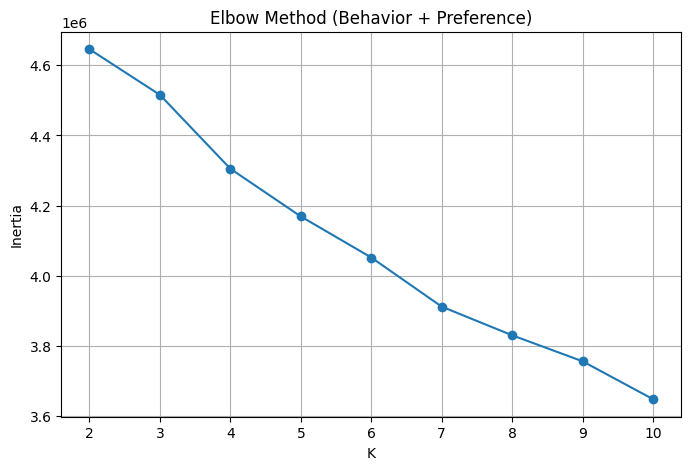

In [7]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(scaled_features)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(K_range, inertia, marker='o')

plt.title("Elbow Method (Behavior + Preference)")
plt.xlabel("K")
plt.ylabel("Inertia")

plt.grid(True)

plt.show()

In [8]:
kmeans = KMeans(
    n_clusters=9,
    random_state=42
)

clusters = kmeans.fit_predict(
    scaled_features
)

enhanced_features["cluster"] = clusters

In [9]:
cluster_summary = enhanced_features.groupby(
    "cluster"
).mean()

cluster_summary

,total_orders,avg_days_between_orders,reorder_ratio,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
cluster,,,,,,,,,,,,,,,,,,,,,
0,11.626587,16.056950,0.429827,0.001950,0.003338,0.022525,0.057768,0.012743,0.001489,0.027319,...,0.012434,0.004836,0.023277,0.001910,0.000773,0.046416,0.008099,0.000695,0.490069,0.055695
1,9.793878,17.347323,0.294326,0.005489,0.003036,0.031871,0.074341,0.016652,0.000861,0.046347,...,0.023648,0.072109,0.024741,0.002419,0.001209,0.080008,0.015604,0.002222,0.260529,0.069769
2,43.978886,7.922109,0.684675,0.003755,0.008751,0.038800,0.079829,0.022119,0.001198,0.028064,...,0.018993,0.006793,0.021022,0.001812,0.000996,0.054820,0.011937,0.001912,0.301151,0.083892
3,9.367021,18.349991,0.305337,0.005754,0.004438,0.049391,0.075219,0.026151,0.000500,0.055929,...,0.028795,0.006669,0.033104,0.001323,0.001133,0.095951,0.015455,0.002512,0.216602,0.074179
4,10.878845,16.319063,0.386676,0.004605,0.003696,0.034069,0.092954,0.024879,0.000433,0.024273,...,0.024943,0.004658,0.017784,0.008437,0.001196,0.050060,0.018239,0.003590,0.161558,0.095143
5,11.218747,17.637094,0.321830,0.103174,0.006094,0.020327,0.125027,0.017357,0.000096,0.016776,...,0.192192,0.003362,0.009913,0.002337,0.008606,0.052912,0.105004,0.033586,0.087023,0.067965
6,10.916558,17.069684,0.413771,0.004693,0.003137,0.046228,0.079976,0.018831,0.000755,0.022600,...,0.014944,0.004777,0.019257,0.001621,0.000935,0.048394,0.011600,0.001783,0.241817,0.095960
7,16.863455,14.535102,0.420121,0.002493,0.209295,0.029387,0.061213,0.019892,0.000445,0.025452,...,0.030662,0.005138,0.016445,0.002912,0.002385,0.041945,0.019460,0.001972,0.201112,0.065587
8,13.462091,16.343033,0.487219,0.007553,0.001324,0.019226,0.323618,0.036422,0.001714,0.007402,...,0.032511,0.002174,0.005663,0.001503,0.000934,0.034353,0.013739,0.001140,0.111551,0.247740


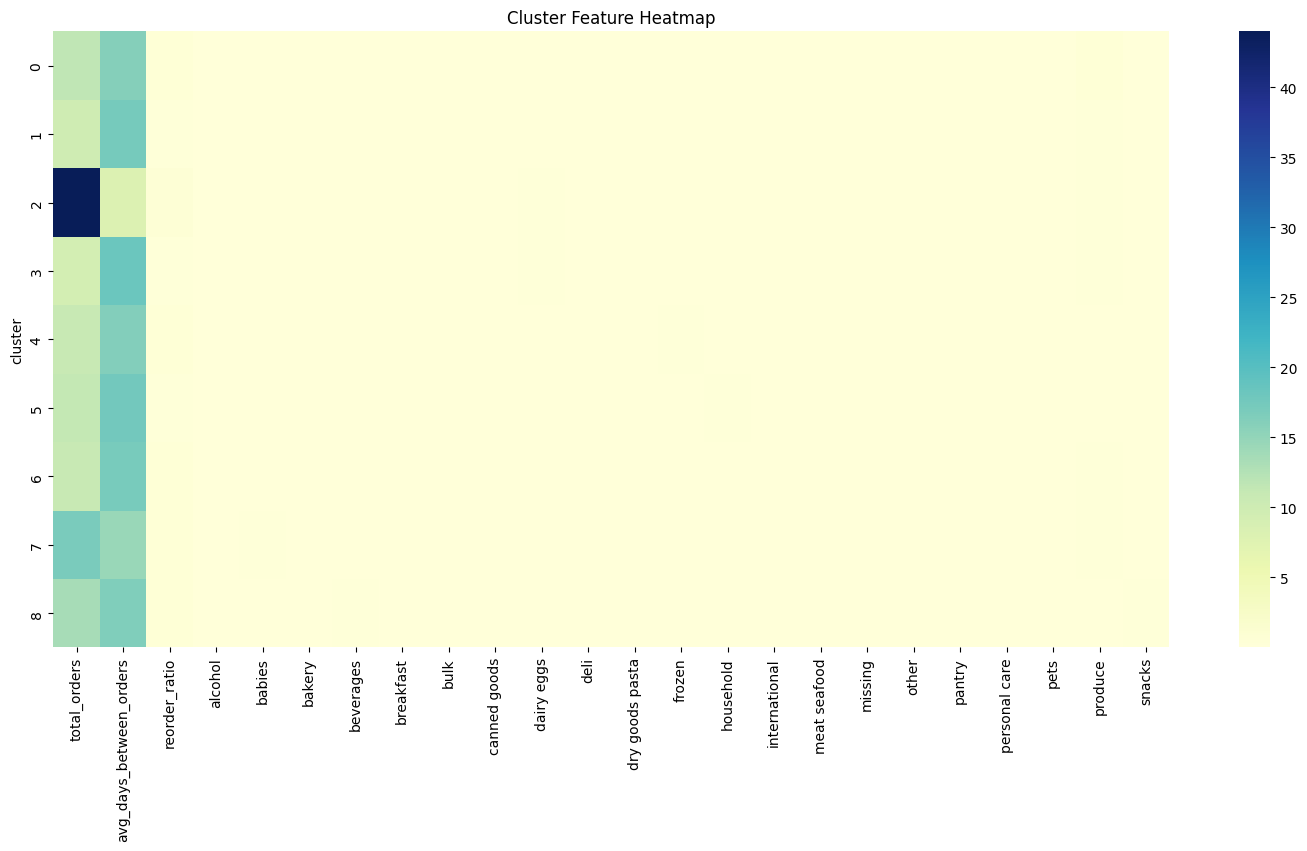

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))

sns.heatmap(
    cluster_summary,
    cmap="YlGnBu",
    annot=False
)

plt.title("Cluster Feature Heatmap")

plt.show()

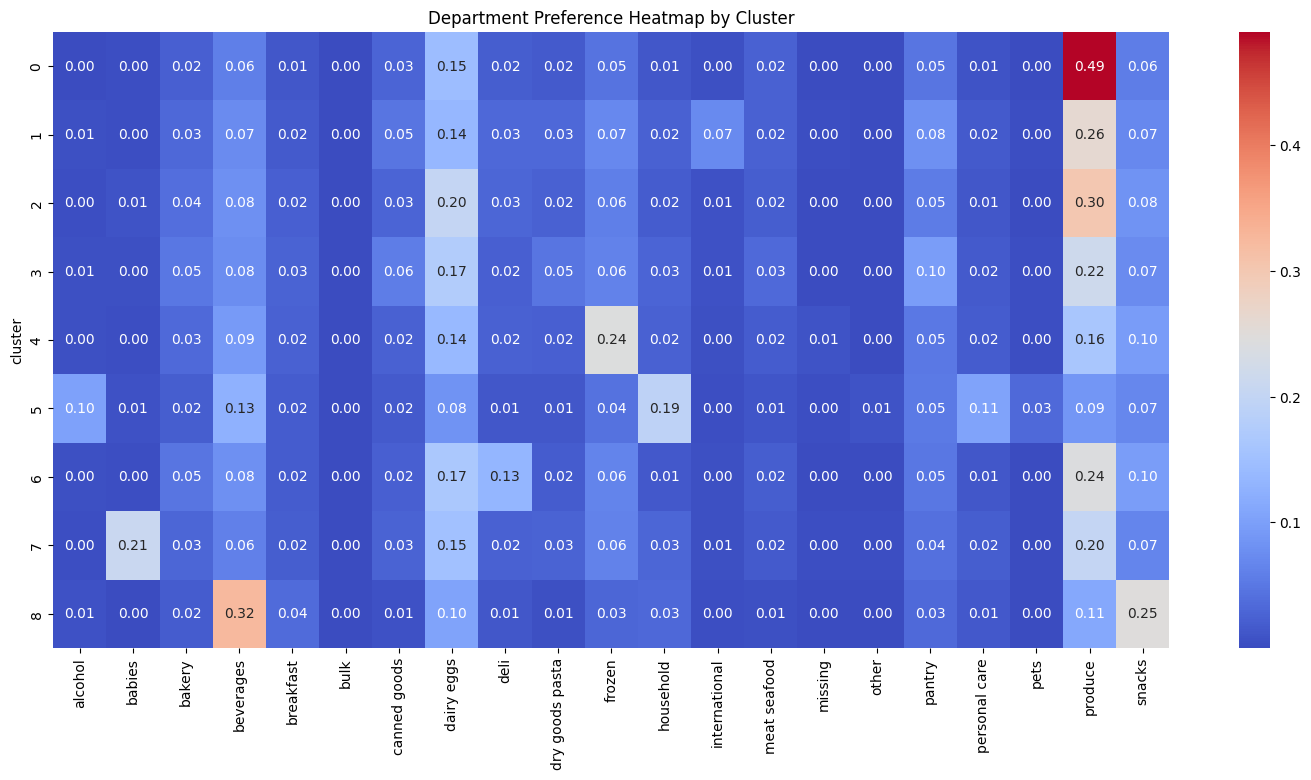

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

department_columns = [
    "alcohol",
    "babies",
    "bakery",
    "beverages",
    "breakfast",
    "bulk",
    "canned goods",
    "dairy eggs",
    "deli",
    "dry goods pasta",
    "frozen",
    "household",
    "international",
    "meat seafood",
    "missing",
    "other",
    "pantry",
    "personal care",
    "pets",
    "produce",
    "snacks"
]

plt.figure(figsize=(18,8))

sns.heatmap(
    cluster_summary[department_columns],
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Department Preference Heatmap by Cluster")

plt.show()

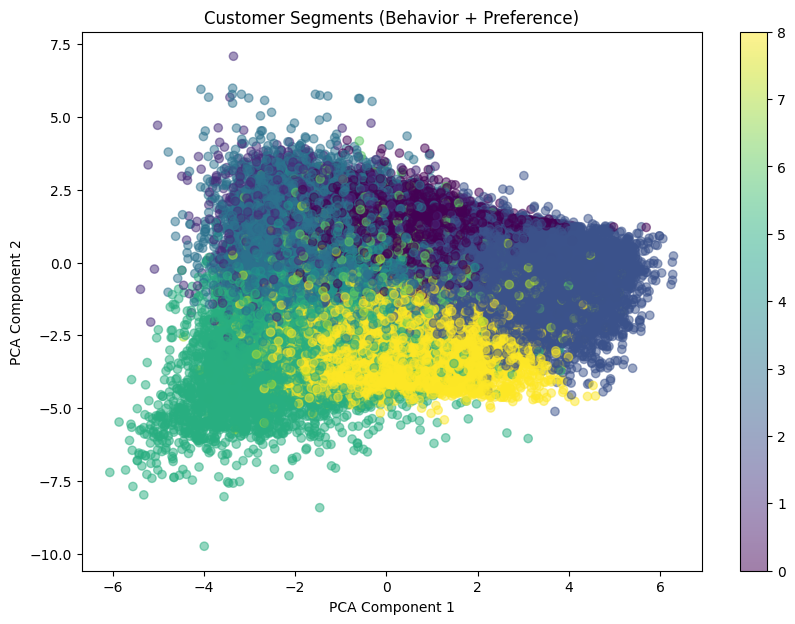

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_result = pca.fit_transform(scaled_features)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=enhanced_features["cluster"],
    cmap="viridis",
    alpha=0.5
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title("Customer Segments (Behavior + Preference)")

plt.colorbar(scatter)

plt.show()

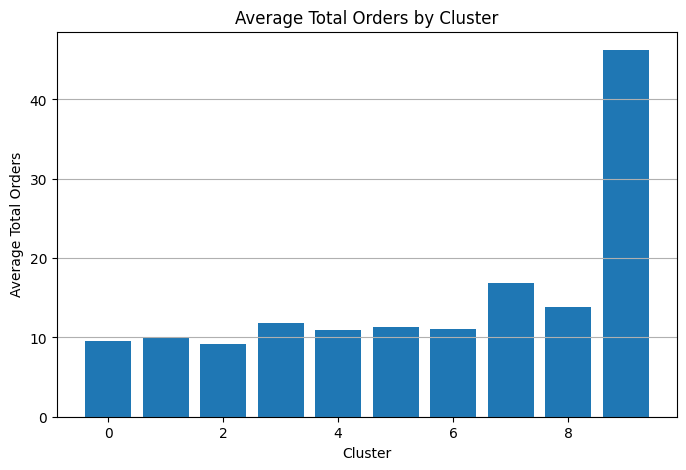

In [98]:
import matplotlib.pyplot as plt

cluster_summary = enhanced_features.groupby("cluster").mean()

plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["total_orders"]
)

plt.title("Average Total Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Total Orders")

plt.grid(axis="y")

plt.show()

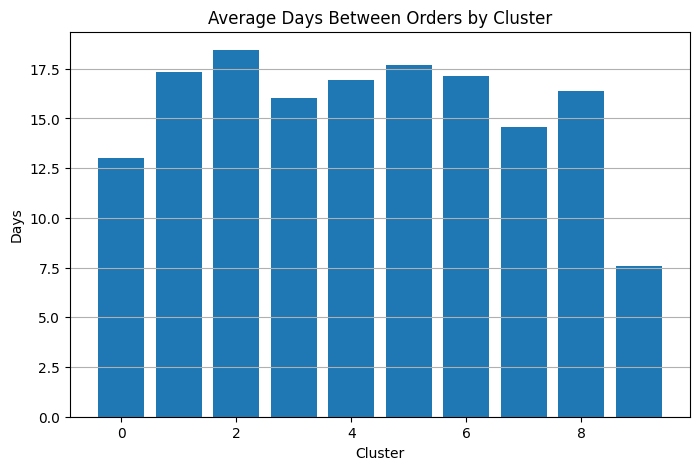

In [99]:
plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["avg_days_between_orders"]
)

plt.title("Average Days Between Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Days")

plt.grid(axis="y")

plt.show()

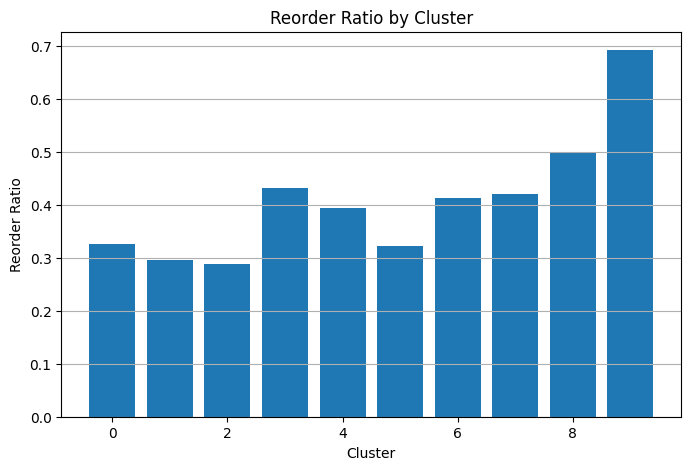

In [100]:
plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["reorder_ratio"]
)

plt.title("Reorder Ratio by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Reorder Ratio")

plt.grid(axis="y")

plt.show()

In [101]:
# 每筆訂單商品數
order_size = (
    order_products_prior
    .groupby("order_id")
    .size()
    .reset_index(name="basket_size")
)

# merge user_id
order_size = order_size.merge(
    orders[["order_id", "user_id"]],
    on="order_id",
    how="left"
)

# merge cluster
order_size = order_size.merge(
    enhanced_features[["cluster"]],
    left_on="user_id",
    right_index=True,
    how="left"
)

order_size.head()

,order_id,basket_size,user_id,cluster
0,2,9,202279,2
1,3,8,205970,9
2,4,13,178520,9
3,5,26,156122,9
4,6,3,22352,2


In [102]:
cluster_basket_size = (
    order_size
    .groupby("cluster")["basket_size"]
    .mean()
)

cluster_basket_size

cluster
0     9.078943
1     9.225147
2    10.723356
3     9.868808
4    10.483190
5     6.365184
6     9.233163
7    12.480920
8     6.276757
9    10.680541
Name: basket_size, dtype: float64

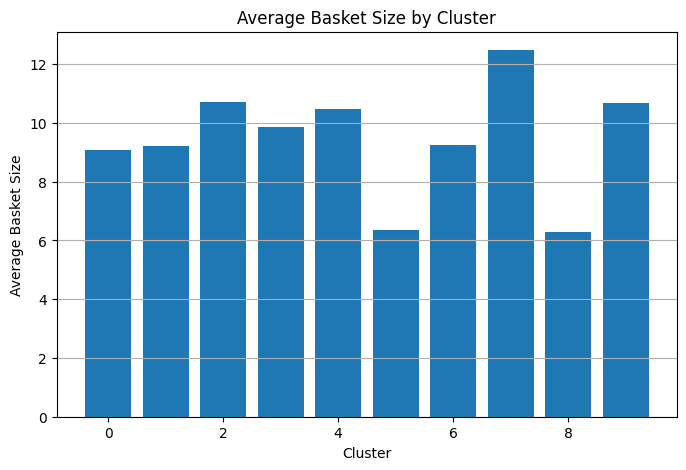

In [103]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    cluster_basket_size.index,
    cluster_basket_size.values
)

plt.title("Average Basket Size by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Basket Size")

plt.grid(axis="y")

plt.show()